In [134]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt


In [135]:
symbols = ['NVDA', 'TSLA', 'AAPL','AMZN', 'QSG', 'INTR', 'BABB','PANL']

In [136]:
data = yf.download(symbols, start="2023-06-01", end="2024-06-01")['Adj Close']
data.head(100)

[*********************100%***********************]  8 of 8 completed


Ticker,AAPL,AMZN,BABB,INTR,NVDA,PANL,QSG,TSLA
Date,,,,,,,,
2023-06-01,178.734894,122.769997,0.642394,2.794331,39.747845,5.435449,9.458197,207.520004
2023-06-02,179.588409,124.250000,0.642394,2.913662,39.305088,5.609310,8.536821,213.970001
2023-06-05,178.228714,125.300003,0.642394,2.993216,39.149178,5.719117,8.339384,217.610001
2023-06-06,177.861511,126.610001,0.642394,3.251766,38.632465,5.664214,8.226562,221.309998
2023-06-07,176.481979,121.230003,0.633594,3.202045,37.457993,5.673364,8.179553,224.570007
...,...,...,...,...,...,...,...,...
2023-10-17,176.054413,131.470001,0.632986,4.077137,43.921684,5.717902,2.162411,254.850006
2023-10-18,174.752518,128.130005,0.632986,4.097026,42.180332,5.671340,2.256429,242.679993
2023-10-19,174.374878,128.399994,0.651072,4.136803,42.085369,5.513026,2.303437,220.110001


In [137]:
def daily_return(symbol):
  daily_return = data[symbol].pct_change()

  plt.plot(daily_return)
  plt.title(f'{symbol}')
  plt.show()
  return daily_return


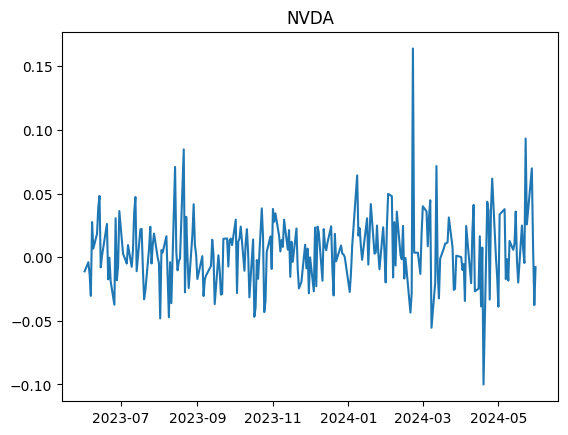

NVDA daily return is significantly different from 0 with p_value 0.012070082670053554


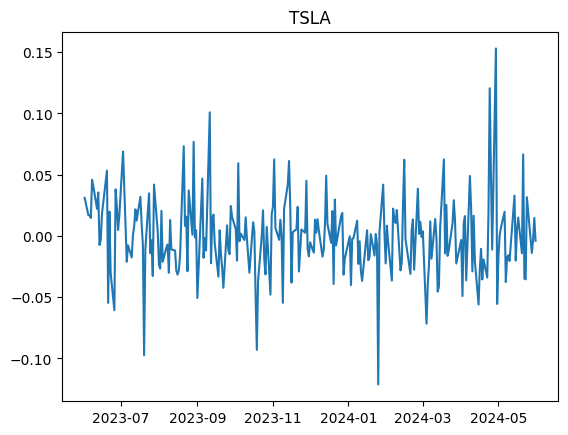

TSLA daily return is not significantly different from 0 with p_value 0.963108909679285


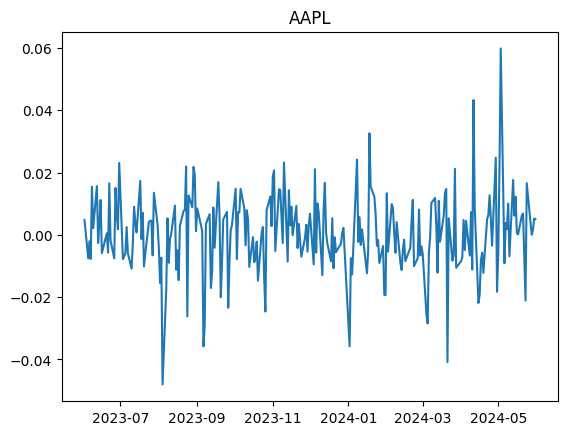

AAPL daily return is not significantly different from 0 with p_value 0.6528349903705422


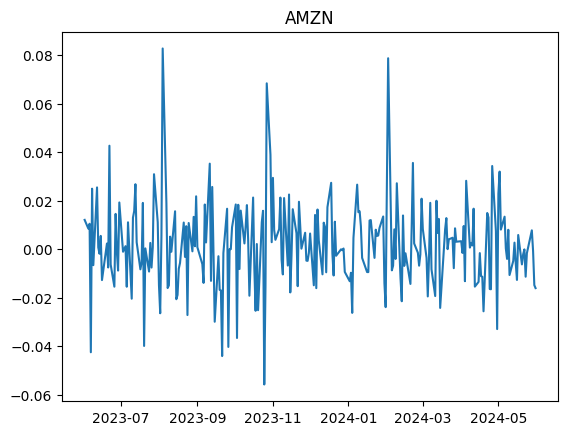

AMZN daily return is not significantly different from 0 with p_value 0.1535603061384686


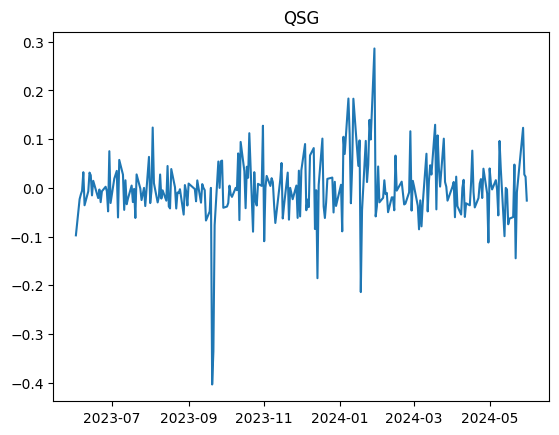

QSG daily return is not significantly different from 0 with p_value 0.46773945695364205


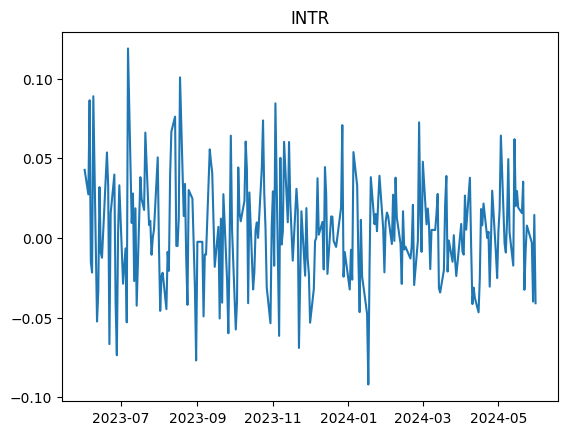

INTR daily return is not significantly different from 0 with p_value 0.08719728011426954


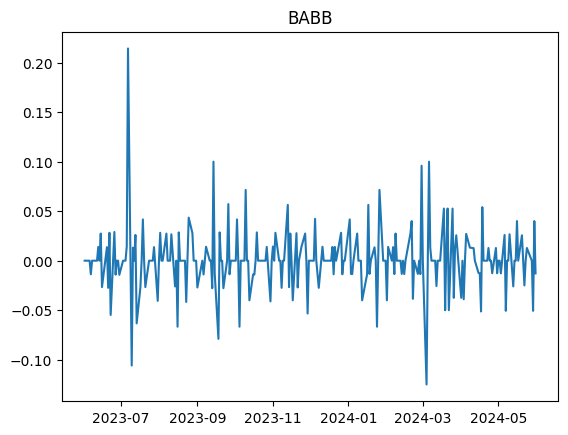

BABB daily return is not significantly different from 0 with p_value 0.6261363965997171


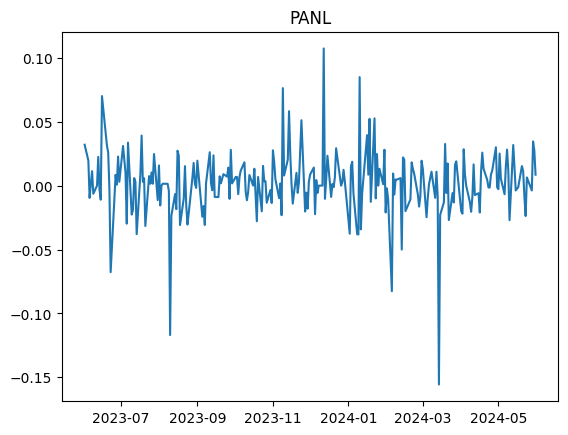

PANL daily return is not significantly different from 0 with p_value 0.23964569396257696


In [138]:
from scipy.stats import ttest_1samp
def stat_check(symbol):
  data = daily_return(symbol).dropna()
  mean = np.mean(data)
  std = np.std(data)
  if mean == 0:
    print (f'{symbol} mean return is 0')
  else:
    t_stat, p_value = ttest_1samp(data, 0)
    if p_value < 0.05:
      print(f'{symbol} daily return is significantly different from 0 with p_value {p_value}')
    else:
      print(f'{symbol} daily return is not significantly different from 0 with p_value {p_value}')
for symbol in symbols:
  stat_check(symbol)



In [139]:
def sharpe(symbol):
  returns = daily_return(symbol)

  average_daily_return = np.mean(returns)
  daily_volatility = np.std(returns)
  risk_free_rate = 0

  # Annualize return and volatility
  annualized_return = (1 + average_daily_return) ** 252 - 1
  annualized_volatility = daily_volatility * np.sqrt(252)

  # Calculate annual Sharpe Ratio
  sharpe_ratio_annual = (annualized_return - risk_free_rate) / annualized_volatility
  return (sharpe_ratio_annual)


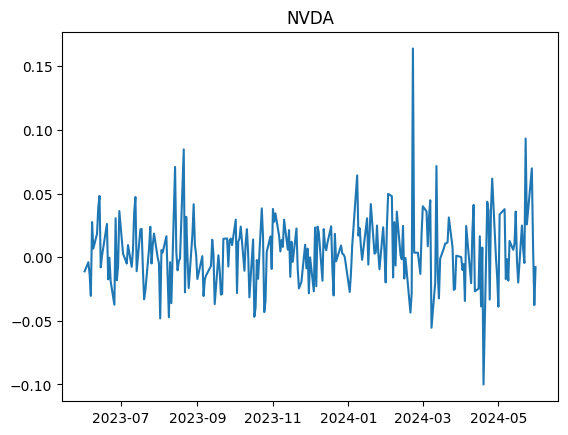

NVDA sharpe is 4.6503819479048


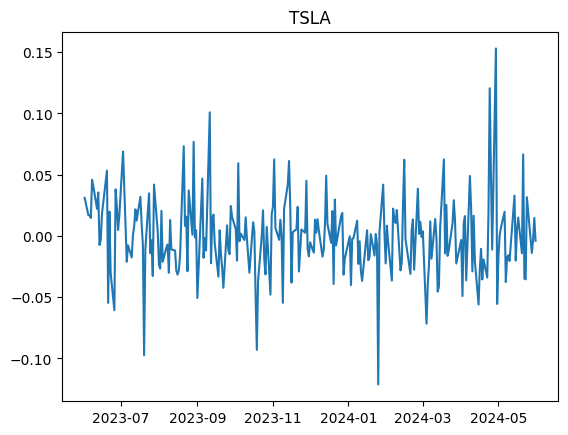

TSLA sharpe is -0.045937829066793126


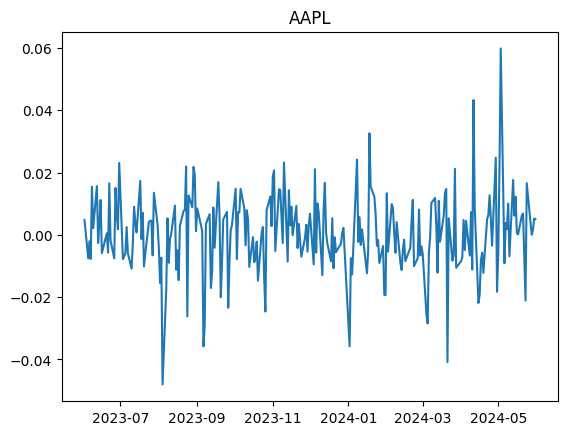

AAPL sharpe is 0.47336440695653675


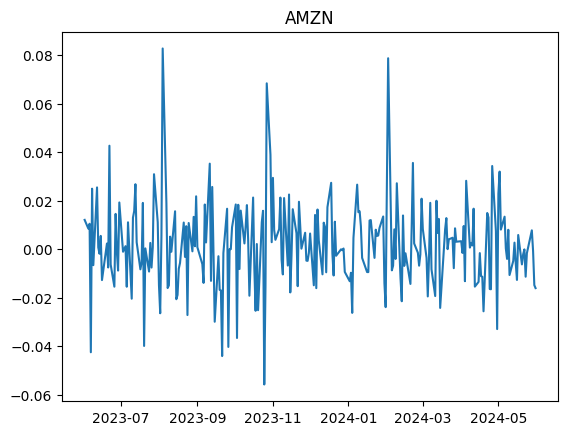

AMZN sharpe is 1.7685856991827227


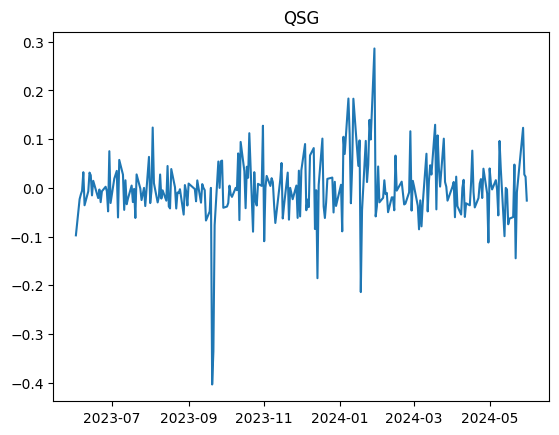

QSG sharpe is -0.5111035299977442


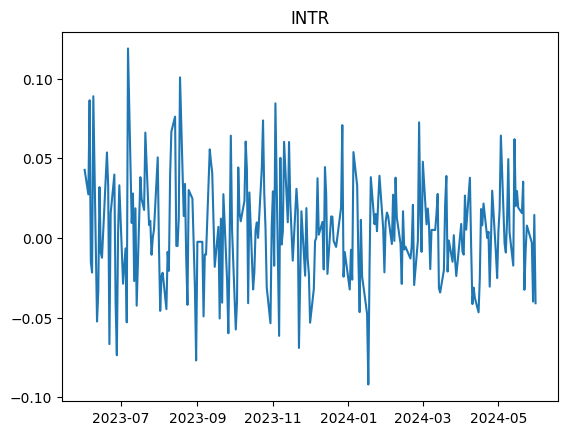

INTR sharpe is 2.827542856898471


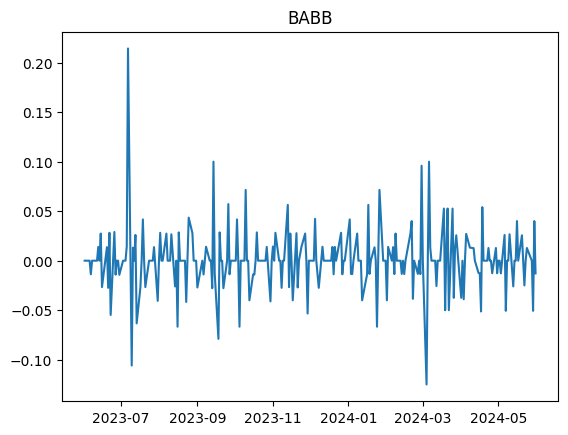

BABB sharpe is 0.5538721208842322


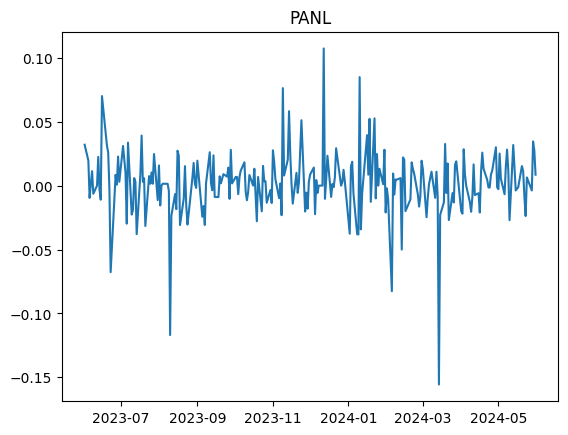

PANL sharpe is 1.5081805040007135


In [140]:
for symbol in symbols:
  sh = sharpe(symbol)
  print (f'{symbol} sharpe is {sh}')

In [141]:
def daily_growth(symbol):
  daily_return = data[symbol].pct_change()+1
  final_return = daily_return.cumprod()
  plt.plot(final_return)
  plt.title(f'{symbol}')
  plt.show()
  return final_return.iloc[-1]

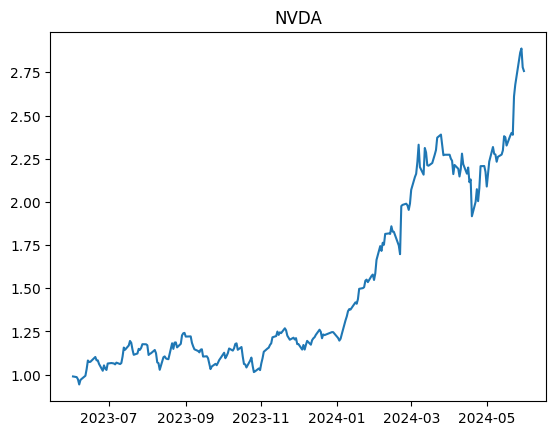

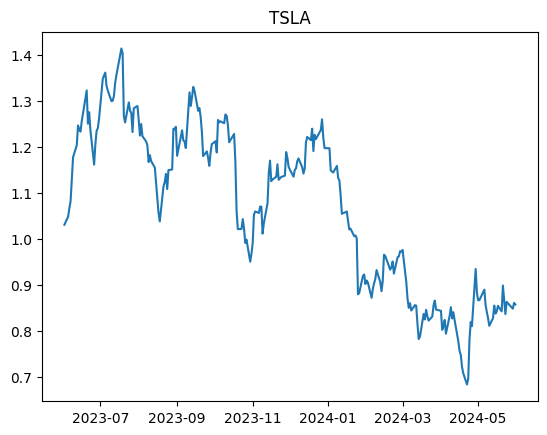

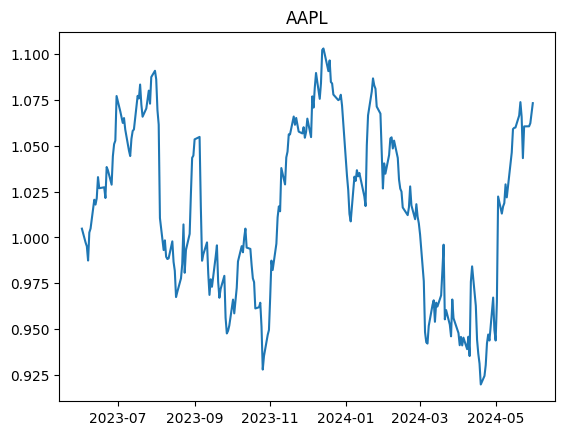

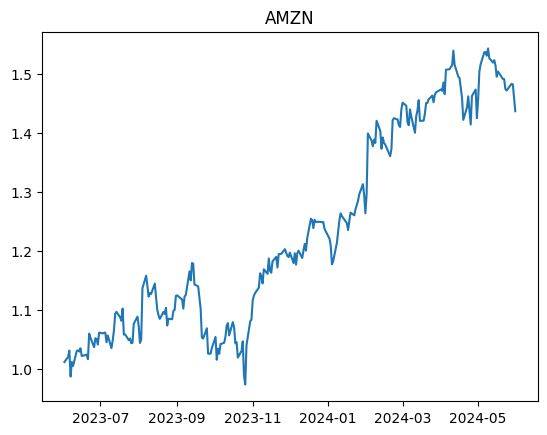

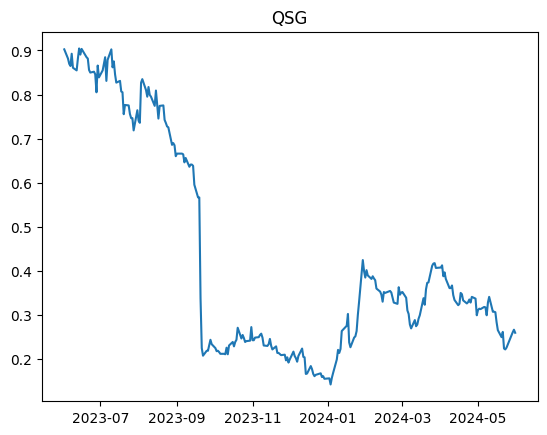

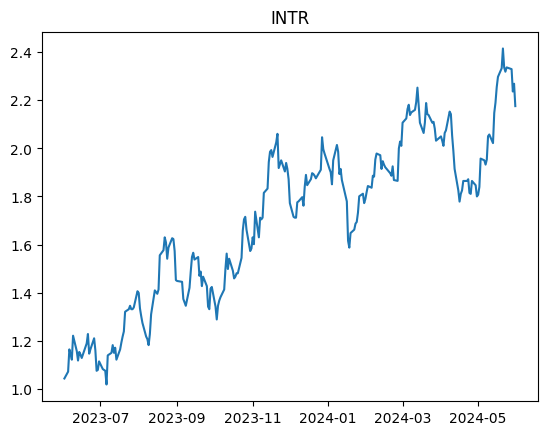

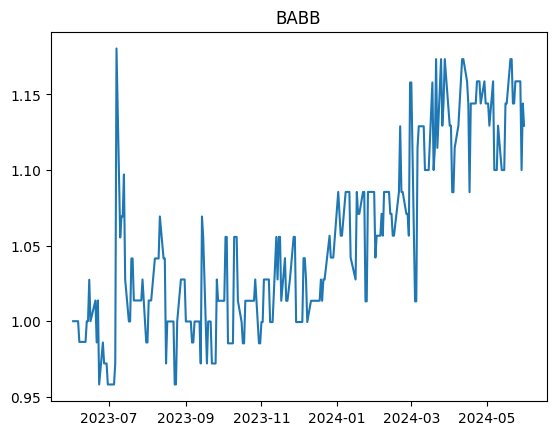

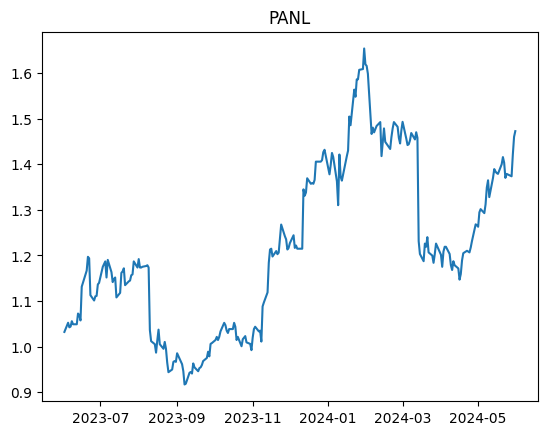

In [142]:
for symbol in symbols:
  daily_growth(symbol)

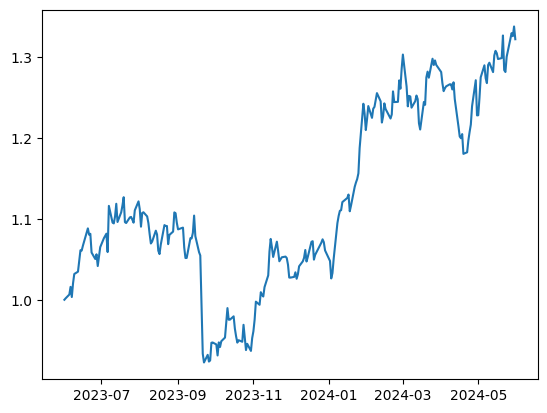

sharpe port is 1.5482529403129068


In [143]:
#calculate equal weight portfolio
num_stocks = len(symbols)
port_ew = np.repeat(1/num_stocks, num_stocks)
data_returns = data.pct_change()
port_daily_ret = data_returns.iloc[:,0:num_stocks].mul(port_ew,axis=1).sum(axis = 1)
port_growth = (port_daily_ret + 1).cumprod()
average_daily_return = np.mean(port_daily_ret)
daily_volatility = np.std(port_daily_ret)
risk_free_rate = 0
# Annualize return and volatility
annualized_return = (1 + average_daily_return) ** 252 - 1
annualized_volatility = daily_volatility * np.sqrt(252)
annualized_sharpe = (annualized_return - risk_free_rate) / annualized_volatility
# port_ret.head()
plt.plot(port_growth)
plt.show()
print(f'sharpe port is {annualized_sharpe}')

